# 02 — Text Models

What's in here:
- **unsupervised** — text → TF-IDF → SVD → KMeans clusters + a t-SNE map ( main thing, base for the website)
- **classification** — can the text guess an aesthetic's era? (Naive Bayes, Logistic Regression, SVC, RandomForest)
- the PyTorch stuff is in `03`

How do I know it's working? The wiki already says which aesthetics are "related", so a good map should put those close together-— using the links as an answer key. Plus silhouette scores, cluster words, confusion matrices and just looking at the map.

Run `01` first.

## Setup

In [1]:
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py" -O data_utils.py
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/text_utils.py" -O text_utils.py
!mkdir -p output

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC

from data_utils import display_confusion_matrix, distance_score, balance_score, silhouette_score
from text_utils import get_top_words

In [4]:
aes_df = pd.read_csv("data/clean/aesthetics_clean.csv")

# empty text instead of NaN, so the vectorizers and string checks work
for col in ["motifs", "colours", "values", "tags_text", "overview", "description"]:
  aes_df[col] = aes_df[col].fillna("")

names = list(aes_df["title"])
print(aes_df.shape)

(1022, 13)


Custom stop words (like the movie reviews): super common words, infobox labels, leftover image names, and all numbers / decades so the era model can't just read "2010s".

In [5]:
stop_list = ["aesthetic", "aesthetics", "style", "styles", "core", "known", "based", "associated",
             "key", "motifs", "colours", "colors", "values", "related", "media", "brands", "decade", "origin",
             "file", "jpg", "png"]

for i in range(2030):
  stop_list.append(str(i))
  stop_list.append(str(i) + "s")

custom_stop_words = list(ENGLISH_STOP_WORDS.union(stop_list))

The wiki's links (Zenodo)-- only pairs where both aesthetics are in table, both directions.

In [6]:
edges_df = pd.read_csv("data/zenodo/wiki_ecosystem_edges.csv")
name_set = set(names)

linked = set()
for a, b in zip(edges_df["aesthetic"], edges_df["related"]):
  if a in name_set and b in name_set and a != b:
    linked.add((a, b))
    linked.add((b, a))

link_counts = {}
for name in names:
  link_counts[name] = 0
for a, b in linked:
  link_counts[a] += 1

n_links = []
for name in names:
  n_links.append(link_counts[name])
aes_df["n_links"] = n_links

print("linked pairs:", len(linked) // 2)
print("aesthetics with at least one link:", (aes_df["n_links"] > 0).sum())

linked pairs: 3544
aesthetics with at least one link: 725


---
# 1. Tuning the map

For 100 random aesthetics that have links: find their 5 nearest neighbours, and check how many of those the wiki also links → `link_hits`.

Random baseline = what you'd get if the "neighbours" were random.

Trying:
- **text:** tags / overview / description
- **n-grams:** single words vs. words + pairs
- **SVD components:** 10 vs. 50

(distance = same as `dist()`, takes about a minute)

In [7]:
eval_idxs = list(aes_df[aes_df["n_links"] > 0].sample(100, random_state=1010).index)

total = 0
for i in eval_idxs:
  total += aes_df["n_links"][i] / (len(names) - 1)
random_hits = total / len(eval_idxs)

print("random baseline link_hits:", round(random_hits, 4))

random baseline link_hits: 0.01


In [8]:
eval_rows = []

for text_col in ["tags_text", "overview", "description"]:
  for ngrams in [(1, 1), (1, 2)]:
    vec = TfidfVectorizer(stop_words=custom_stop_words, min_df=3, max_df=0.5, max_features=20_000, ngram_range=ngrams)
    vct = vec.fit_transform(aes_df[text_col])

    for n_comp in [10, 50]:
      feats_list = TruncatedSVD(n_components=n_comp, random_state=1010).fit_transform(vct).tolist()

      hits = 0
      for i in eval_idxs:
        dists = []
        for j in range(len(names)):
          s = 0
          for a, b in zip(feats_list[i], feats_list[j]):
            s += (a - b) ** 2
          dists.append(s ** 0.5)

        for j in pd.Series(dists).sort_values().index[1:6]:
          if (names[i], names[j]) in linked:
            hits += 1

      eval_rows.append({"text": text_col, "ngrams": str(ngrams), "svd_components": n_comp,
                        "link_hits": round(hits / (5 * len(eval_idxs)), 3)})
      print(text_col, ngrams, n_comp, "->", eval_rows[-1]["link_hits"])

link_eval_df = pd.DataFrame(eval_rows).sort_values("link_hits", ascending=False)
link_eval_df.to_csv("output/link_eval.csv", index=False)
link_eval_df

tags_text (1, 1) 10 -> 0.056
tags_text (1, 1) 50 -> 0.082
tags_text (1, 2) 10 -> 0.062
tags_text (1, 2) 50 -> 0.076
overview (1, 1) 10 -> 0.022
overview (1, 1) 50 -> 0.03
overview (1, 2) 10 -> 0.016
overview (1, 2) 50 -> 0.034
description (1, 1) 10 -> 0.108
description (1, 1) 50 -> 0.2
description (1, 2) 10 -> 0.106
description (1, 2) 50 -> 0.202


,text,ngrams,svd_components,link_hits
11,description,"(1, 2)",50,0.202
9,description,"(1, 1)",50,0.200
8,description,"(1, 1)",10,0.108
10,description,"(1, 2)",10,0.106
1,tags_text,"(1, 1)",50,0.082
3,tags_text,"(1, 2)",50,0.076
2,tags_text,"(1, 2)",10,0.062
0,tags_text,"(1, 1)",10,0.056
7,overview,"(1, 2)",50,0.034
5,overview,"(1, 1)",50,0.030


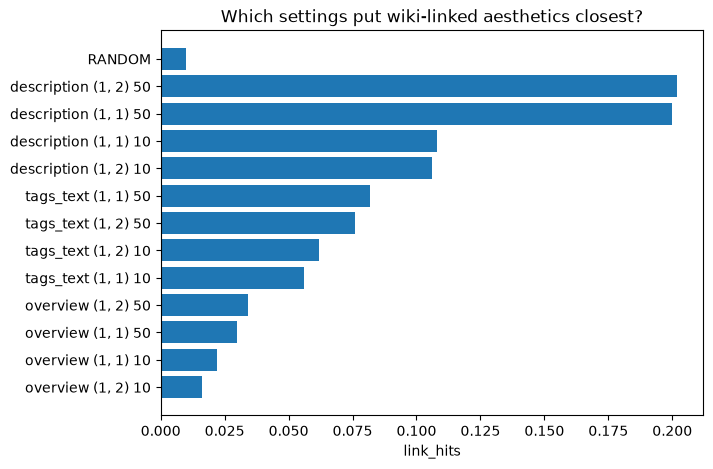

In [9]:
labels = ["RANDOM"]
values = [random_hits]
for t, ng, nc, h in zip(link_eval_df["text"], link_eval_df["ngrams"], link_eval_df["svd_components"], link_eval_df["link_hits"]):
  labels.append(t + " " + ng + " " + str(nc))
  values.append(h)

plt.figure(figsize=(7, 5))
plt.barh(labels[::-1], values[::-1])
plt.xlabel("link_hits")
plt.title("Which settings put wiki-linked aesthetics closest?")
plt.show()

Setting the final settings from the top row:

In [10]:
BEST_TEXT = "description"
BEST_NGRAMS = (1, 2)
BEST_COMPONENTS = 50

---
# 2. Final vectors + topics

In [11]:
vec = TfidfVectorizer(stop_words=custom_stop_words, min_df=3, max_df=0.5, max_features=20_000, ngram_range=BEST_NGRAMS)
vct = vec.fit_transform(aes_df[BEST_TEXT])
vocab = vec.get_feature_names_out()

svd = TruncatedSVD(n_components=BEST_COMPONENTS, random_state=1010)
feats = svd.fit_transform(vct)

print(vct.shape, "->", feats.shape)
print("explained variance:", round(sum(svd.explained_variance_ratio_), 3))

(1022, 20000) -> (1022, 50)
explained variance: 0.254


Topics = top words of the first 10 SVD components:

In [12]:
topics = get_top_words(svd.components_[:10], vocab, n_words=8)
for i in range(len(topics)):
  print("topic", i, topics[i])

topic 0 ['yé', 'girl', 'tiktok', 'preppy', 'gamer', 'boys', 'bon', 'kei']
topic 1 ['pop', 'metal', 'rock', 'art', 'music', 'rap', 'punk', 'artists']
topic 2 ['art', 'school', 'realism', 'century', 'impressionism', 'futurism', 'nouveau', 'movement']
topic 3 ['girl', 'y2k', 'crush', 'dark', 'academia', 'frutiger', 'green', 'cyber']
topic 4 ['crush', 'y2k', 'mtv', 'cyber', '2k', 'futurism', 'y2k futurism', 'sky']
topic 5 ['girl', 'summer', 'coastal', 'winter', 'clean girl', 'clean', 'dopamine', 'brazilian']
topic 6 ['frutiger', 'aero', 'frutiger aero', 'metro', 'design', 'flat', 'corporate', 'eco']
topic 7 ['academia', 'frutiger', 'dark', 'light academia', 'knowledge', 'aero', 'academic', 'learning']
topic 8 ['kawaii', 'anime', 'japanese', 'pastel', 'girly', 'pink', 'kei', 'cute']
topic 9 ['summer', 'carnival', 'winter', 'kawaii', 'saint', 'summer winter', 'chinese', 'thanksgiving']


---
# 3. Clusters

### How many?

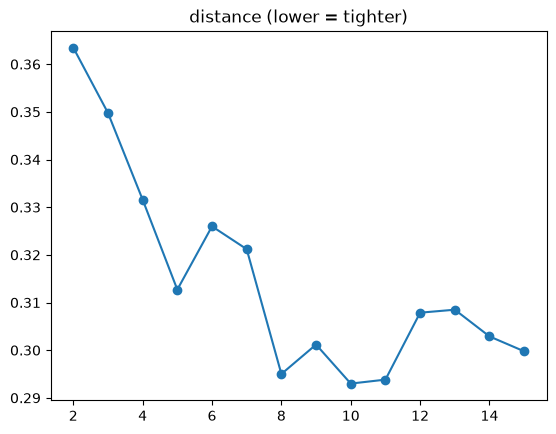

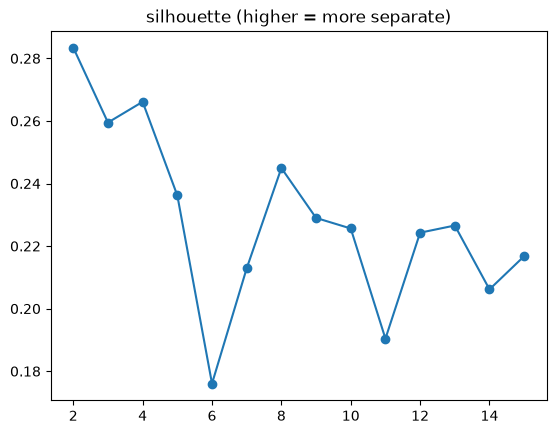

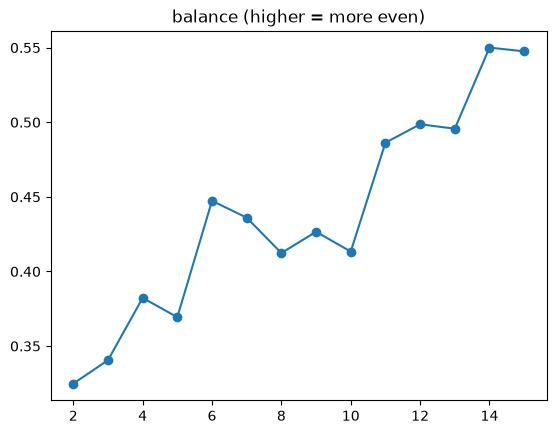

In [13]:
ks = list(range(2, 16))
dist_scores = []
sil_scores = []
bal_scores = []

for k in ks:
  pred = KMeans(n_clusters=k, random_state=1010).fit_predict(feats)
  dist_scores.append(distance_score(feats, pred))
  sil_scores.append(silhouette_score(feats, pred))
  bal_scores.append(balance_score(pred))

plt.plot(ks, dist_scores, marker="o")
plt.title("distance (lower = tighter)")
plt.show()
plt.plot(ks, sil_scores, marker="o")
plt.title("silhouette (higher = more separate)")
plt.show()
plt.plot(ks, bal_scores, marker="o")
plt.title("balance (higher = more even)")
plt.show()

### The clusters

Pick `K` from the plots. Centers are in SVD space, so `inverse_transform()` puts them back into words (like un-PCA-ing the faces) for `get_top_words()`.

In [14]:
K = 10

km = KMeans(n_clusters=K, random_state=1010)
aes_df["cluster"] = km.fit_predict(feats)

cluster_words = get_top_words(svd.inverse_transform(km.cluster_centers_), vocab, n_words=8)

for c in range(K):
  in_c = aes_df[aes_df["cluster"] == c]
  print("CLUSTER", c, "-", len(in_c), "aesthetics")
  print("  words:", cluster_words[c])
  print("  e.g.:", list(in_c["title"].head(10)))
  print("  eras:", list(in_c["era"].value_counts().index[:3]))
  print()

CLUSTER 0 - 587 aesthetics
  words: ['music', 'dark', 'popular', 'people', 'elements', 'visuals', 'common', 'used']
  e.g.: ['Femme Fatale', 'Indicolite', 'Kingcore', 'Onii Kei', 'Pin-up', 'Acidwave', 'Yandere', 'Coffinwood', 'Kawaii', 'Whimsigothic']
  eras: ['unknown', 'pre-internet', 'Tumblr']

CLUSTER 1 - 27 aesthetics
  words: ['girl', 'coastal', 'summer', 'clean', 'clean girl', 'dopamine', 'vanilla', 'beige']
  e.g.: ['LOLcore', 'Avant Basic', '2020 Alt', 'Tomato Girl Summer', 'Earthy Black Girl', 'Sad Beige', 'Dopamine', 'Mob Wife', 'New Spanish Catholic Girl', 'Succubus Chic']
  eras: ['TikTok', 'unknown', 'Tumblr']

CLUSTER 2 - 60 aesthetics
  words: ['art', 'school', 'movement', 'realism', 'impressionism', 'futurism', 'nouveau', 'figuration']
  e.g.: ['Impressionism', 'Neue Slowenische Kunst', 'Purism', 'Mexican Muralism', 'Bauhaus', 'Romanesque', 'Surrealism', 'Plakatstil', 'Minimalism', 'Newlyn School']
  eras: ['pre-internet', 'unknown', 'Old Web']

CLUSTER 3 - 75 aestheti

---
# 4. Map

t-SNE on the SVD features. Larger black dots = my favorites.

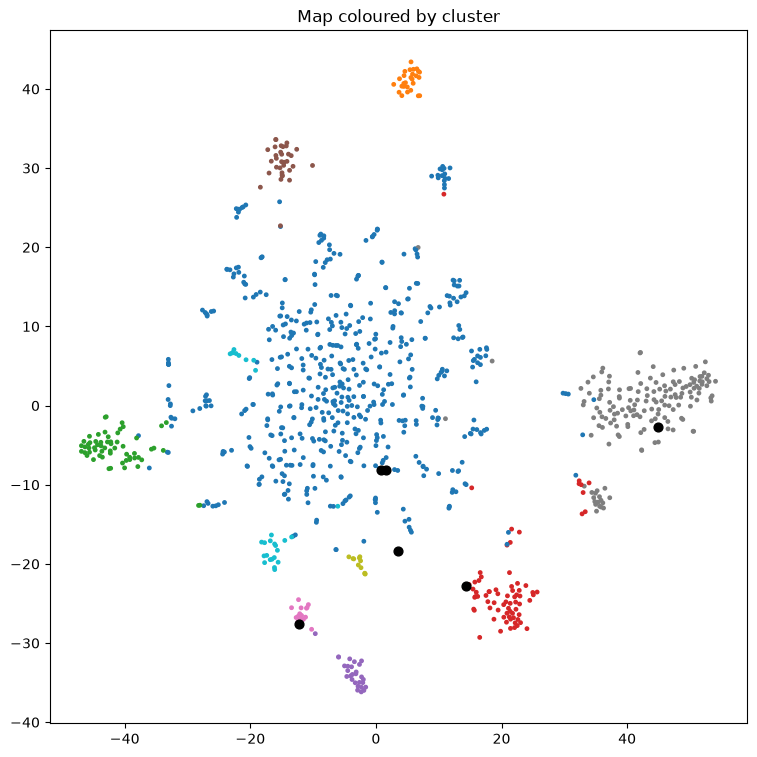

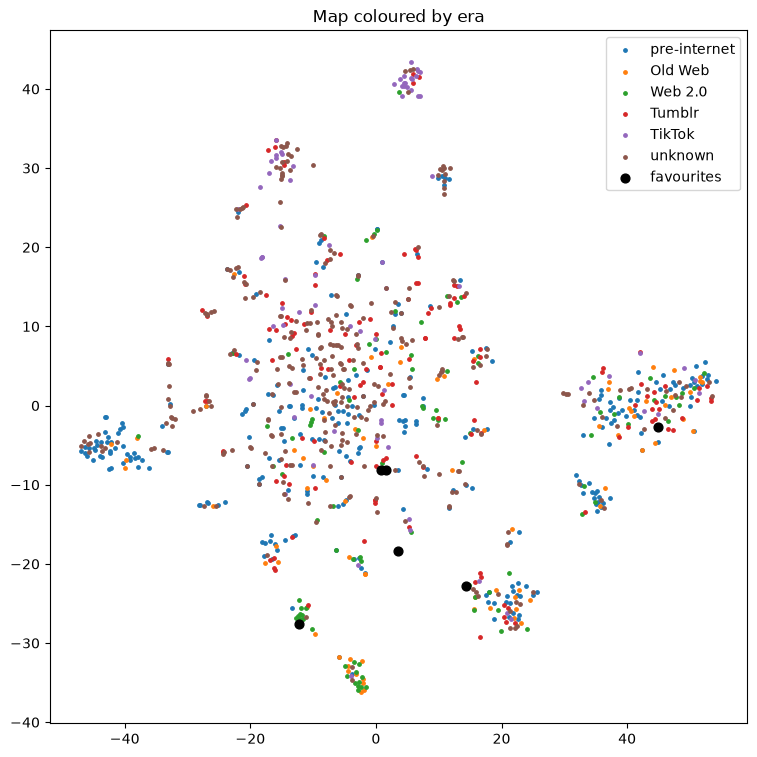

,title,cluster,era,map_x,map_y
295,Dreamcore,0,Tumblr,1.672076,-8.142989
548,Webcore,0,Old Web,3.483318,-18.310482
712,Seapunk,7,Web 2.0,44.986794,-2.669874
809,Weirdcore,0,Tumblr,0.851034,-8.093453
884,Vaporwave,3,Tumblr,14.310126,-22.845873
938,Frutiger Aero,6,Web 2.0,-12.274165,-27.540882


In [15]:
favorites = ["Vaporwave", "Frutiger Aero", "Webcore", "Weirdcore", "Dreamcore", "Seapunk"]

tsne = TSNE(n_components=2, random_state=1010).set_output(transform="pandas")
map_df = tsne.fit_transform(feats)

aes_df["map_x"] = map_df["tsne0"].values
aes_df["map_y"] = map_df["tsne1"].values
fav_df = aes_df[aes_df["title"].isin(favorites)]

plt.figure(figsize=(9, 9))
plt.scatter(aes_df["map_x"], aes_df["map_y"], c=aes_df["cluster"], cmap="tab10", s=6)
plt.scatter(fav_df["map_x"], fav_df["map_y"], c="black", s=40)
plt.title("Map coloured by cluster")
plt.show()

era_order = ["pre-internet", "Old Web", "Web 2.0", "Tumblr", "TikTok", "unknown"]

plt.figure(figsize=(9, 9))
for era in era_order:
  in_era = aes_df[aes_df["era"] == era]
  plt.scatter(in_era["map_x"], in_era["map_y"], s=6, label=era)
plt.scatter(fav_df["map_x"], fav_df["map_y"], c="black", s=40, label="favourites")
plt.legend()
plt.title("Map coloured by era")
plt.show()

display(fav_df[["title", "cluster", "era", "map_x", "map_y"]])

---
# 5. Neighbours for every aesthetic

Top 5 closest for each one (for the website's connections) + whether the wiki links them.

In [17]:
feats_list = feats.tolist()
neighbour_rows = []

for i in range(len(names)):
  dists = []
  for j in range(len(names)):
    s = 0
    for a, b in zip(feats_list[i], feats_list[j]):
      s += (a - b) ** 2
    dists.append(s ** 0.5)

  rank = 1
  for j in pd.Series(dists).sort_values().index[1:6]:
    neighbour_rows.append({"title": names[i], "neighbour": names[j], "rank": rank,
                           "distance": round(dists[j], 4), "linked": (names[i], names[j]) in linked})
    rank += 1

neighbours_df = pd.DataFrame(neighbour_rows)
print("all neighbours that are wiki-linked:", round(neighbours_df["linked"].mean(), 3))

all neighbours that are wiki-linked: 0.146


Closest pairs the wiki *doesn't* link = connections the text finds on its own:

In [18]:
not_linked_df = neighbours_df[(neighbours_df["linked"] == False) & (neighbours_df["rank"] == 1)]
display(not_linked_df.sort_values("distance").head(15))

for fav in favorites:
  fav_n = neighbours_df[neighbours_df["title"] == fav]
  print(fav, "->", list(fav_n["neighbour"]), list(fav_n["linked"]))

,title,neighbour,rank,distance,linked
255,Purism,Suprematism,1,0.0422,False
3725,Suprematism,Purism,1,0.0422,False
885,Eshay,Ah Beng,1,0.0533,False
2140,Ah Beng,Eshay,1,0.0533,False
3060,Racaille,Swenkas,1,0.0553,False
3880,Swenkas,Racaille,1,0.0553,False
4440,Blokecore,Eshay,1,0.0615,False
1350,80s Cool,Racaille,1,0.0667,False
3085,Post-Impressionism,Purism,1,0.0687,False
455,Beatnik,80s Cool,1,0.0701,False


Vaporwave -> ['Synthwave', 'Trillwave', 'Lo-Fi', 'Breakcore', 'Denpa (music genre)'] [True, True, False, False, False]
Frutiger Aero -> ['Frutiger Metro', 'Dark Aero', 'Frutiger Aurora', 'Bright Tertiaries', 'Frutiger Eco'] [False, False, False, True, True]
Webcore -> ['Shibuya Punk', 'Kaiwai Kyoku', 'Silicon Dreams', '90s Cool', '2000s Ringtone Mascot'] [False, False, True, False, False]
Weirdcore -> ['Voidcore', 'Dreamcore', 'Hydrogen', 'Poolcore', 'Golden Hour'] [False, True, False, True, False]
Dreamcore -> ['Weirdcore', 'Poolcore', 'Hydrogen', 'Voidcore', 'Dreamy'] [True, True, False, False, False]
Seapunk -> ['Sadpeople', 'Tecktonik', 'Drain', 'Jersey Shore', 'Doomer'] [False, False, False, False, False]


---
# 6. Can the text guess the era?

balance the labels (class code), then split.

In [19]:
era_df = aes_df[aes_df["era"] != "unknown"]
min_count = era_df["era"].value_counts().min()

def sample_min(df):
  return df.sample(min_count, random_state=1010)

rg = era_df.groupby("era")
era_balanced_df = rg[era_df.columns].apply(sample_min).reset_index(drop=True)

era_train_df, era_test_df = train_test_split(era_balanced_df, test_size=0.2, random_state=1010)
era_labels = sorted(era_balanced_df["era"].unique())

print(min_count, "per era -", len(era_train_df), "train /", len(era_test_df), "test")
print("random guess:", round(1 / len(era_labels), 3))

81 per era - 324 train / 81 test
random guess: 0.2


### Baseline: simple features

Like the character / word counts for the movie reviews.

In [20]:
simple_cols = ["n_tags", "overview_words"]

simple_model = RandomForestClassifier(random_state=1010)
simple_model.fit(era_train_df[simple_cols], era_train_df["era"])

print("train:", round(accuracy_score(era_train_df["era"], simple_model.predict(era_train_df[simple_cols])), 3))
print("test:", round(accuracy_score(era_test_df["era"], simple_model.predict(era_test_df[simple_cols])), 3))

train: 0.867
test: 0.235


### Which text × which model?

In [21]:
model_names = ["MultinomialNB", "LogisticRegression", "SVC (linear)", "RandomForest"]
era_rows = []

for text_col in ["tags_text", "overview", "description"]:
  era_vec = TfidfVectorizer(stop_words=custom_stop_words, min_df=2, max_df=0.75, max_features=20_000, ngram_range=BEST_NGRAMS)
  train_vct = era_vec.fit_transform(era_train_df[text_col])
  test_vct = era_vec.transform(era_test_df[text_col])

  for model_name in model_names:
    if model_name == "MultinomialNB":
      model = MultinomialNB()
    elif model_name == "LogisticRegression":
      model = LogisticRegression(max_iter=1000)
    elif model_name == "SVC (linear)":
      model = SVC(kernel="linear")
    else:
      model = RandomForestClassifier(random_state=1010)

    model.fit(train_vct, era_train_df["era"])
    era_rows.append({"text": text_col, "model": model_name,
                     "train": round(accuracy_score(era_train_df["era"], model.predict(train_vct)), 3),
                     "test": round(accuracy_score(era_test_df["era"], model.predict(test_vct)), 3)})

era_models_df = pd.DataFrame(era_rows).sort_values("test", ascending=False)
era_models_df.to_csv("output/era_models.csv", index=False)
era_models_df

,text,model,train,test
5,overview,LogisticRegression,0.944,0.432
8,description,MultinomialNB,0.793,0.420
4,overview,MultinomialNB,0.923,0.407
10,description,SVC (linear),0.889,0.407
6,overview,SVC (linear),0.938,0.395
9,description,LogisticRegression,0.907,0.383
11,description,RandomForest,1.000,0.370
7,overview,RandomForest,1.000,0.333
0,tags_text,MultinomialNB,0.923,0.321
1,tags_text,LogisticRegression,0.948,0.296


### Best one in detail

Set these from the top row above.

              precision    recall  f1-score   support

     Old Web       0.25      0.57      0.35        14
      TikTok       0.50      0.56      0.53        16
      Tumblr       0.67      0.29      0.40        21
     Web 2.0       0.38      0.19      0.25        16
pre-internet       0.57      0.57      0.57        14

    accuracy                           0.42        81
   macro avg       0.47      0.44      0.42        81
weighted avg       0.49      0.42      0.42        81



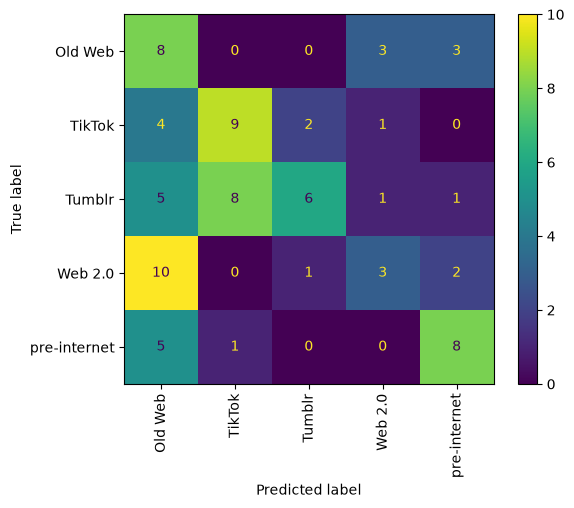

In [22]:
ERA_TEXT = "description"

era_vec = TfidfVectorizer(stop_words=custom_stop_words, min_df=2, max_df=0.75, max_features=20_000, ngram_range=BEST_NGRAMS)
train_vct = era_vec.fit_transform(era_train_df[ERA_TEXT])
test_vct = era_vec.transform(era_test_df[ERA_TEXT])

era_model = MultinomialNB()
era_model.fit(train_vct, era_train_df["era"])
test_preds = era_model.predict(test_vct)

print(classification_report(era_test_df["era"], test_preds))
display_confusion_matrix(era_test_df["era"], test_preds, era_labels)

Top words per era (join all the era's text, vectorize, `get_top_words()`):

In [23]:
era_vocab = era_vec.get_feature_names_out()

for era in era_labels:
  era_text = " ".join(era_balanced_df[era_balanced_df["era"] == era][ERA_TEXT])
  print(era, get_top_words(era_vec.transform([era_text]), era_vocab, n_words=10))

Old Web ['music', 'yé', 'rock', 'metal', 'new', 'art', 'culture', 'pop', 'girl', 'like']
TikTok ['girl', 'academia', 'fashion', 'tiktok', 'like', 'summer', 'trend', 'dark', 'new', 'online']
Tumblr ['girl', 'cottagecore', 'like', 'yé', 'morute', 'kawaii', 'tiktok', 'music', 'community', 'traumacore']
Web 2.0 ['frutiger', 'aero', 'frutiger aero', 'music', 'metro', 'anime', 'new', 'like', 'scene', 'yé']
pre-internet ['art', 'new', 'pop', 'culture', 'yé', 'music', 'hipster', 'fashion', 'girl', 'movement']


### What about less data?

Training on 25 / 50 / 75 / 100% of the train set

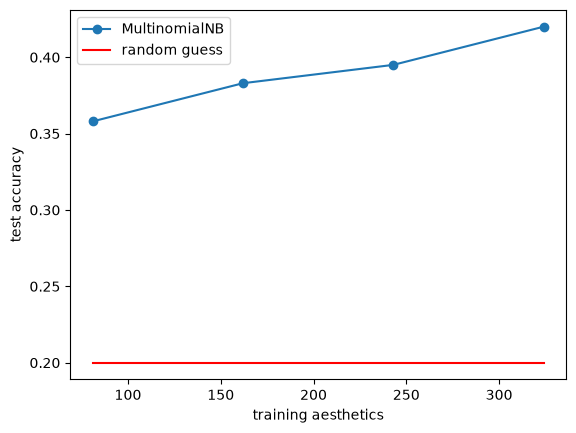

,train_size,test
0,81,0.358
1,162,0.383
2,243,0.395
3,324,0.420


In [24]:
size_rows = []

for pct in [0.25, 0.5, 0.75, 1.0]:
  part_df = era_train_df.sample(n=int(len(era_train_df) * pct), random_state=1010)

  size_vec = TfidfVectorizer(stop_words=custom_stop_words, min_df=2, max_df=0.75, max_features=20_000, ngram_range=BEST_NGRAMS)
  part_vct = size_vec.fit_transform(part_df[ERA_TEXT])

  size_model = MultinomialNB()
  size_model.fit(part_vct, part_df["era"])
  test_acc = accuracy_score(era_test_df["era"], size_model.predict(size_vec.transform(era_test_df[ERA_TEXT])))
  size_rows.append({"train_size": len(part_df), "test": round(test_acc, 3)})

era_size_df = pd.DataFrame(size_rows)
era_size_df.to_csv("output/era_data_size.csv", index=False)

plt.plot(era_size_df["train_size"], era_size_df["test"], marker="o", label="MultinomialNB")
plt.plot(era_size_df["train_size"], [1 / len(era_labels)] * len(era_size_df), color="red", label="random guess")
plt.xlabel("training aesthetics")
plt.ylabel("test accuracy")
plt.legend()
plt.show()

era_size_df

---
# 7. Save (for the report + website)

In [25]:
map_cols = ["title", "era", "decade", "cluster", "map_x", "map_y", "n_links", "motifs", "colours", "values", "overview"]
aes_df[map_cols].to_csv("output/aesthetics_map.csv", index=False)

neighbours_df.to_csv("output/aesthetics_neighbours.csv", index=False)

cluster_rows = []
for c in range(K):
  cluster_rows.append({"cluster": c, "size": (aes_df["cluster"] == c).sum(), "words": ", ".join(cluster_words[c])})
pd.DataFrame(cluster_rows).to_csv("output/cluster_words.csv", index=False)

link_rows = []
for a, b in linked:
  if a < b:
    link_rows.append({"a": a, "b": b})
pd.DataFrame(link_rows).to_csv("output/aesthetics_links.csv", index=False)

!ls -la output

total 696
drwxrwxrwx+ 2 codespace codespace   4096 Nov 25 04:09 .
drwxrwxrwx+ 5 codespace root        4096 Nov 25 04:00 ..
-rw-rw-rw-  1 codespace codespace  78850 Nov 25 04:09 aesthetics_links.csv
-rw-rw-rw-  1 codespace codespace 407257 Nov 25 04:09 aesthetics_map.csv
-rw-rw-rw-  1 codespace codespace 195498 Nov 25 04:09 aesthetics_neighbours.csv
-rw-rw-rw-  1 codespace codespace    765 Nov 25 04:09 cluster_words.csv
-rw-rw-rw-  1 codespace codespace     54 Nov 25 04:09 era_data_size.csv
-rw-rw-rw-  1 codespace codespace    461 Nov 25 04:09 era_models.csv
-rw-rw-rw-  1 codespace codespace    374 Nov 25 04:02 link_eval.csv
